# 17b · Phase 3 results: which training change lowers false flags on unseen topics?

`17_augment.ipynb` fixed, **before any variant was trained**, the experiment and the decision rule (committed as `a09db22`). This notebook only applies that rule; nothing in the design was changed afterwards. In short:

- Seven leave-one-prompt-out folds chosen by rule from 16b (the four worst prompts, the median, the two best), one seed (42), compared prompt by prompt with the saved original-recipe folds.
- **Primary statistic:** mean over the seven prompts of the left-out human false-flag rate at the val-chosen 1% threshold, variant minus original recipe, paired bootstrap interval (thresholds redrawn too).
- **Secondary (reported, not decisive):** worst-prompt rate; false-flag rate among the most predictable quarter of humans (GPT-2 log-perplexity below 3.0473).
- **Guardrail:** val AI caught at the 1% threshold must not drop by more than 0.5 points.
- **A variant wins** iff the primary interval is below zero and the guardrail holds. Variant C (A + B) was run only because the primary point estimates of A and B were both below zero. If several variants win, the one with the most negative primary estimate is trained on the full set (3 seeds); if none wins, the original recipe is.

The comparison code is `src/compare.py`. The held-out prompts and held-out generators are not scored anywhere in this phase.

In [1]:
import os
os.environ['HF_HUB_OFFLINE'] = '1'
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_splits
from src.compare import analyse, report
from src.evaluate import wilson_interval, threshold_for_fpr, auc_with_interval

SEED = 42
pd.set_option('display.width', 230); pd.set_option('display.max_colwidth', 100)
HUMAN, AI, GREEN = '#2a78d6', '#eb6834', '#2d7d46'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e3', 'grid.linewidth': 0.6, 'axes.edgecolor': '#9a9a94', 'axes.titleweight': 'bold'})
data = load_splits()
log_ppl = pd.read_csv('../results/10_gpt2_features.csv', index_col='row_id')['log_ppl']
FOLDS = [11, 4, 3, 6, 7, 12, 2]     # the pre-registered folds, printed in 17_augment.ipynb (fold index = prompt, sorted by name)
for v in 'ABC':
    n = len([f for f in os.listdir(f'../results/17_variants/{v}') if f.startswith('scores_')])
    print(f'variant {v}: {n} fold score files')

variant A: 13 fold score files
variant B: 7 fold score files
variant C: 7 fold score files


## 1 · Each variant against the original recipe

In [2]:
res = {}
res['A'] = report('A', FOLDS, data, log_ppl)

=== VARIANT A against the original recipe, 7 folds, seed 42 ===
                             n humans  baseline flagged  baseline % baseline Wilson  variant flagged  variant % variant Wilson  difference (pts)
prompt                                                                                                                                          
Seeking multiple opinions        1552                90        5.80    [4.74, 7.07]               83       5.35   [4.33, 6.58]             -0.45
Distance learning                2157               119        5.52    [4.63, 6.56]               63       2.92   [2.29, 3.72]             -2.60
Community service                1542                80        5.19    [4.19, 6.41]               46       2.98   [2.24, 3.96]             -2.20
Exploring Venus                  1862                88        4.73    [3.85, 5.79]               99       5.32   [4.39, 6.43]              0.59
Facial action coding system      2167                55        2.5

In [3]:
res['B'] = report('B', FOLDS, data, log_ppl)

=== VARIANT B against the original recipe, 7 folds, seed 42 ===
                             n humans  baseline flagged  baseline % baseline Wilson  variant flagged  variant % variant Wilson  difference (pts)
prompt                                                                                                                                          
Seeking multiple opinions        1552                90        5.80    [4.74, 7.07]              109       7.02   [5.86, 8.40]              1.22
Distance learning                2157               119        5.52    [4.63, 6.56]               72       3.34   [2.66, 4.18]             -2.18
Community service                1542                80        5.19    [4.19, 6.41]               44       2.85   [2.13, 3.81]             -2.33
Exploring Venus                  1862                88        4.73    [3.85, 5.79]              117       6.28   [5.27, 7.48]              1.56
Facial action coding system      2167                55        2.5

In [4]:
res['C'] = report('C', FOLDS, data, log_ppl)

=== VARIANT C against the original recipe, 7 folds, seed 42 ===
                             n humans  baseline flagged  baseline % baseline Wilson  variant flagged  variant % variant Wilson  difference (pts)
prompt                                                                                                                                          
Seeking multiple opinions        1552                90        5.80    [4.74, 7.07]               71       4.57   [3.64, 5.73]             -1.22
Distance learning                2157               119        5.52    [4.63, 6.56]               86       3.99   [3.24, 4.90]             -1.53
Community service                1542                80        5.19    [4.19, 6.41]               59       3.83   [2.98, 4.90]             -1.36
Exploring Venus                  1862                88        4.73    [3.85, 5.79]               64       3.44   [2.70, 4.37]             -1.29
Facial action coding system      2167                55        2.5

## 2 · The decision

Applied as written in `17_augment.ipynb`: a variant wins iff its primary interval is below zero **and** the guardrail holds; among winners, the most negative primary point estimate is trained on the full training set.

In [5]:
rows = []
for v, (per, o) in res.items():
    rows.append({'variant': v, 'PRIMARY mean diff (pts)': o['primary'][0], 'primary 95% low': o['primary'][1], 'primary 95% high': o['primary'][2],
                 'worst prompt: base -> variant': f"{o['worst'][0]:.2f}% -> {o['worst'][1]:.2f}%",
                 'predictable quarter: base -> variant': f"{o['predictable quarter'][0]:.2f}% -> {o['predictable quarter'][1]:.2f}%",
                 'predictable quarter diff [95%]': f"{o['predictable quarter'][2]:+.2f} [{o['predictable quarter'][3]:+.2f}, {o['predictable quarter'][4]:+.2f}]",
                 'guardrail (val AI caught, pts)': f"{o['guardrail'][0]:+.2f} [{o['guardrail'][1]:+.2f}, {o['guardrail'][2]:+.2f}]",
                 'guardrail holds': o['guardrail_ok'], 'WINS': o['wins']})
summary = pd.DataFrame(rows).set_index('variant')
summary.round(3).to_csv('../results/17_variant_summary.csv')
pd.concat([per.assign(variant=v) for v, (per, o) in res.items()]).round(4).to_csv('../results/17_variant_by_prompt.csv')
winners = [v for v in res if res[v][1]['wins']]
winner = min(winners, key=lambda v: res[v][1]['primary'][0]) if winners else 'original recipe'
a_ok, b_ok = res['A'][1]['primary'][0] < 0, res['B'][1]['primary'][0] < 0
print(f"C was required to run: primary point estimates of A and B both below zero: A {a_ok}, B {b_ok}")
print(f"variants that WIN: {winners or 'none'}  ->  trained on the full training set: {winner}")
summary.round(3)

C was required to run: primary point estimates of A and B both below zero: A True, B True
variants that WIN: ['A', 'C']  ->  trained on the full training set: A


,PRIMARY mean diff (pts),primary 95% low,primary 95% high,worst prompt: base -> variant,predictable quarter: base -> variant,predictable quarter diff [95%],"guardrail (val AI caught, pts)",guardrail holds,WINS
variant,,,,,,,,,
A,-0.864,-1.495,-0.260,5.80% -> 5.35%,8.30% -> 5.66%,"-2.64 [-4.30, -1.28]","+0.04 [-0.06, +0.20]",True,True
B,-0.170,-0.605,0.335,5.80% -> 7.02%,8.30% -> 7.39%,"-0.91 [-2.26, +0.00]","-0.00 [-0.11, +0.10]",True,False
C,-0.799,-1.577,-0.384,5.80% -> 4.57%,8.30% -> 6.01%,"-2.30 [-4.33, -1.37]","+0.10 [-0.06, +0.22]",True,True


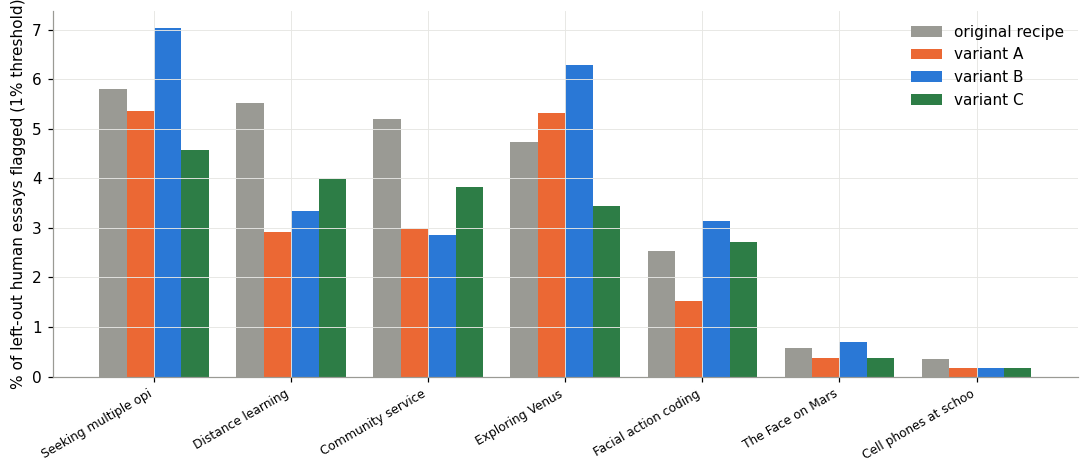

In [6]:
# one picture: false-flag rate by left-out prompt, original recipe and the three variants
per0 = res['A'][0]
order = per0.sort_values('baseline %', ascending=False).index
x = np.arange(len(order)); width = 0.2
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(x - 1.5 * width, per0.loc[order, 'baseline %'], width, label='original recipe', color='#9a9a94')
for j, (v, c) in enumerate(zip('ABC', (AI, HUMAN, GREEN))):
    ax.bar(x + (j - 0.5) * width, res[v][0].loc[order, 'variant %'], width, label=f'variant {v}', color=c)
ax.set_xticks(x); ax.set_xticklabels([p[:20] for p in order], rotation=30, ha='right', fontsize=8)
ax.set_ylabel('% of left-out human essays flagged (1% threshold)'); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig('../images/17_variants_by_prompt.png', dpi=150, bbox_inches='tight'); plt.show()

### Exploratory (not part of the pre-registered rule): is the winner really better than the runner-up?

When two variants both win, the rule picks the more negative primary estimate, even if they are close. The same paired machinery can ask directly: C against A.

In [7]:
per_ca, o_ca = analyse('C', FOLDS, data, log_ppl, base_dir='../results/17_variants/A')
p, w, q = o_ca['primary'], o_ca['worst'], o_ca['predictable quarter']
print(f"C minus A, mean false-flag rate over the 7 prompts: {p[0]:+.3f} points  95% [{p[1]:+.3f}, {p[2]:+.3f}]")
print(f"worst prompt: A {w[0]:.2f}% -> C {w[1]:.2f}%  (difference {w[2]:+.2f} [{w[3]:+.2f}, {w[4]:+.2f}])")
print(f"most predictable quarter: A {q[0]:.2f}% -> C {q[1]:.2f}%  (difference {q[2]:+.2f} [{q[3]:+.2f}, {q[4]:+.2f}])")
print(f"val AI caught, C minus A: {o_ca['guardrail'][0]:+.2f} points [{o_ca['guardrail'][1]:+.2f}, {o_ca['guardrail'][2]:+.2f}]")
per_ca[['baseline %', 'variant %', 'difference (pts)']].rename(columns={'baseline %': 'A %', 'variant %': 'C %'}).round(2)

C minus A, mean false-flag rate over the 7 prompts: +0.065 points  95% [-0.512, +0.299]
worst prompt: A 5.35% -> C 4.57%  (difference -0.77 [-3.11, +0.91])
most predictable quarter: A 5.66% -> C 6.01%  (difference +0.35 [-1.08, +0.92])
val AI caught, C minus A: +0.05 points [-0.09, +0.12]


,A %,C %,difference (pts)
prompt,,,
Seeking multiple opinions,5.35,4.57,-0.77
Distance learning,2.92,3.99,1.07
Community service,2.98,3.83,0.84
Exploring Venus,5.32,3.44,-1.88
Facial action coding system,1.52,2.72,1.20
The Face on Mars,0.38,0.38,0.00
Cell phones at school,0.18,0.18,0.00


## 3 · The final models: the winner trained on the full training set, 3 seeds

The winning recipe was trained on all 28,006 training essays (the augmentation for A; none of the held-out prompts or generators is involved), with seeds 42, 43 and 44, keeping the best epoch by val AUC as in notebook 08. Models are in `models/distilroberta_<tag>_s<seed>/` (git-ignored, ~330 MB each; `aug` = variant A). Only the val and test essays were scored (`results/17_final/`). Per seed, the threshold is the score that flags 1% of **val** humans (notebook 09's rule); test is read to report. The original model of notebook 08 is the comparison.

In [8]:
TAGS = {'A': 'aug', 'B': 'predw', 'C': 'augpredw'}
tag = TAGS.get(winner, 'orig')
base = pd.read_csv('../results/15_scores.csv', index_col='row_id')['roberta']          # the notebook 08 model (first-512), scored in 15
def summarize(name, s):
    s = s.copy()
    vh = s[(s['role'] == 'val') & (s['label'] == 0)]['logit']
    thr = threshold_for_fpr(vh, 0.01)
    t = s[s['role'] == 'test']
    th, ta = t[t['label'] == 0], t[t['label'] == 1]
    k, n = int((th['logit'] >= thr).sum()), len(th); lo, hi = wilson_interval(k, n)
    k2, n2 = int((ta['logit'] >= thr).sum()), len(ta); lo2, hi2 = wilson_interval(k2, n2)
    auc, alo, ahi = auc_with_interval(t['label'], t['logit'], groups=data.loc[t.index, 'dup_cluster'])
    return {'model': name, 'threshold (logit)': round(thr, 3), 'test humans flagged %': f'{100 * k / n:.2f} [{100 * lo:.2f}, {100 * hi:.2f}] ({k}/{n})',
            'test AI caught %': f'{100 * k2 / n2:.2f} [{100 * lo2:.2f}, {100 * hi2:.2f}] ({k2}/{n2})', 'test AUC': f'{auc:.4f} [{alo:.4f}, {ahi:.4f}]'}
rows, final_scores = [], {}
vals = data[data['split'] == 'val']; tests = data[data['split'] == 'test']
orig = pd.concat([pd.DataFrame({'row_id': d.index, 'label': d['label'].to_numpy(), 'role': r, 'logit': base.loc[d.index].to_numpy()}).set_index('row_id') for d, r in ((vals, 'val'), (tests, 'test'))])
rows.append(summarize('original (notebook 08, seed 42)', orig))
for sd in (42, 43, 44):
    path = f'../results/17_final/{tag}_s{sd}_scores.csv'
    if os.path.exists(path):
        s = pd.read_csv(path, index_col='row_id'); final_scores[sd] = s
        assert set(s['split']) <= {'val', 'test'}, 'a held-out split was scored'
        assert os.path.isdir(f'../models/distilroberta_{tag}_s{sd}')
        rows.append(summarize(f'{tag} seed {sd}', s))
pd.DataFrame(rows).set_index('model')

,threshold (logit),test humans flagged %,test AI caught %,test AUC
model,,,,
"original (notebook 08, seed 42)",4.666,"0.92 [0.60, 1.40] (21/2291)","99.50 [98.92, 99.77] (1204/1210)","0.9995 [0.9987, 0.9999]"
aug seed 42,4.568,"0.79 [0.50, 1.24] (18/2291)","99.59 [99.04, 99.82] (1205/1210)","0.9997 [0.9993, 0.9999]"
aug seed 43,3.578,"0.96 [0.64, 1.45] (22/2291)","99.50 [98.92, 99.77] (1204/1210)","0.9998 [0.9996, 0.9999]"
aug seed 44,-0.135,"0.74 [0.46, 1.19] (17/2291)","99.50 [98.92, 99.77] (1204/1210)","0.9998 [0.9995, 0.9999]"


In [9]:
fl = pd.read_csv('../results/17_final/log.csv')
fl = fl[fl['variant'] == (winner if winner in TAGS else 'baseline')]
print(fl[['variant', 'seed', 'minutes', 'best_epoch', 'val_auc', 'peak_gpu_gb']].to_string(index=False))
print('\nsaved model folders:', sorted(d for d in os.listdir('../models') if d.startswith('distilroberta_')))

variant  seed  minutes  best_epoch  val_auc  peak_gpu_gb
      A    42     16.7           2  0.99978          3.2
      A    43     16.6           2  0.99979          3.2
      A    44     16.6           2  0.99988          3.2

saved model folders: ['distilroberta_aug_s42', 'distilroberta_aug_s43', 'distilroberta_aug_s44', 'distilroberta_finetuned']


## Verdict

**By the pre-registered rule, variant A (spelling/typo augmentation) wins and is the model carried forward.** Both A and C satisfy the rule (primary interval below zero, guardrail held); A has the more negative primary estimate.

| | Primary: mean false-flag change, 7 prompts | Predictable quarter of humans | Worst prompt | Guardrail: val AI caught | Wins |
|---|---|---|---|---|---|
| **A** augmentation | **−0.86 [−1.50, −0.26]** | 8.30% → 5.66% (−2.64 [−4.30, −1.28]) | 5.80% → 5.35% (−0.45 [−4.04, +1.56]) | +0.04 [−0.06, +0.20] | **yes** |
| B predictability weights | −0.17 [−0.61, +0.34] | 8.30% → 7.39% (−0.91 [−2.26, 0.00]) | 5.80% → 7.02% (+1.22 [−2.33, +2.90]) | −0.00 [−0.11, +0.10] | no |
| C A + B | −0.80 [−1.58, −0.38] | 8.30% → 6.01% (−2.30 [−4.33, −1.37]) | 5.80% → 4.57% (−1.22 [−4.56, −0.13]) | +0.10 [−0.06, +0.22] | yes |

- **A works, modestly, and not everywhere.** The mean false-flag rate on unseen topics falls by about 0.9 points (from a baseline mean of about 3.5%), mostly through large drops on three prompts (Distance learning 5.52% → 2.92%, Community service 5.19% → 2.98%, Facial action coding system 2.54% → 1.52%) and small drops on three more; **Exploring Venus gets worse (4.73% → 5.32%)**. The worst prompt barely moves (its interval spans zero). The false-flag rate among the most predictable quarter of humans, the group the 16b finding pointed at, falls from 8.3% to 5.7%: still high. Detection is untouched (guardrail +0.04 points).
- **Why it plausibly works:** misspellings were evidence for "human"; after the augmentation the misspelling rate alone separates the classes far less (AUC 0.18 → 0.43 on the training essays, `17_augment.ipynb`), so a fluent, correctly spelled student loses a handicap. That is a plausible mechanism, not something this notebook isolates; no ablation separates "repaired human spelling" from "typos injected in AI essays".
- **B does not help.** Equalising predictability bins gave a primary effect of −0.17 points with an interval spanning zero; it helped two prompts (Distance learning, Community service) and hurt three (Seeking multiple opinions +1.22, Exploring Venus +1.56, Facial action coding +0.60), and the worst prompt got worse. One reason may be that weights up to about 14 leave an effective training sample of about 10,500 essays out of 28,000, so the training is noisier; another is that predictability is a real signal that the network can recover from other cues. Neither is tested here.
- **C is not distinguishable from A.** Exploratory (not part of the rule): C minus A is +0.07 points [−0.51, +0.30]. C is the only variant that improved Exploring Venus (−1.29) and has the best worst-prompt rate (4.57%), but it is worse than A on Distance learning, Community service and Facial action coding. The rule picks A because its primary estimate is more negative; the data cannot say A is better than C. **If a deployment cares most about the worst topic, C is a defensible alternative**; the rule was fixed in advance and is followed here.
- **Final models.** Variant A, trained on all 28,006 training essays, seeds 42, 43, 44 (16.6–16.7 minutes each; `models/distilroberta_aug_s42`, `_s43`, `_s44`). On the test split at each seed's own val-1% threshold, humans flagged are 0.79%, 0.96% and 0.74% against 0.92% for the original model, AI caught 99.59%, 99.50% and 99.50% against 99.50%, and AUC 0.9997–0.9998 against 0.9995. **All of this is within the intervals: on the familiar test set the models are indistinguishable**, which is the saturation the external review pointed out; the benefit shows only on unseen topics.
- **One thing to carry into Phase 5.** The val-chosen 1% thresholds of the three seeds are very different: **+4.57, +3.58 and −0.13 logits**. The seeds disagree in where the humans' scores sit (the 99th percentile of val humans), even though their AUCs are all near 0.9999. A plain average of the three logits is therefore not a clean ensemble; each seed's scores need to be put on a common scale (for example, subtract each seed's threshold) before averaging.
- **Limits.** One seed per fold per variant, seven prompts, so each prompt's difference is a single run (seed noise on one fold was about 0.34 points in 16b); the intervals include the threshold noise and the left-out essay sampling but not training-seed variance. The two held-out prompts and the held-out generators have **not** been scored: they are checked once, at the end of Phase 5.

## Key takeaways

- **A (spelling/typo augmentation) is the winner by the pre-registered rule** and costs nothing at training or inference time: the mean unseen-topic false-flag rate falls by 0.86 points [−1.50, −0.26] with no loss of detection (guardrail +0.04).
- **Predictability weighting (B) failed**; the combination (C) matches A within noise.
- **The residual problem is the same as before:** the worst prompts still sit around 4.6–5.4% and the most predictable quarter of humans at 5.7–6.0%. Phase 4 (a threshold that holds on the worst topic) and Phase 5 (stability) start from these models and from the LOPO scores.
- **Reusable:** `results/17_variants/{A,B,C}/` (fold scores), `17_variant_summary.csv`, `17_variant_by_prompt.csv`, `17_final/` (val and test scores of the three final models), `src/compare.py`, `src/augment.py`, `src/spelling.py`, `scripts/train_variant.py`.
- **Next:** Phase 4 and 5 should use the three `aug` models with per-seed standardised scores; Phase 6 (optional) can test the fairness side the augmentation might affect (it changes how misspellings are treated, which matters for non-native writers).

## 4 · After the fact (NOT pre-registered): variant A on all 13 folds

The seven pre-registered folds were chosen **from the extremes of the original recipe's results** (the four worst prompts, the median, the two best), so they are not a representative sample of topics. Six more folds of variant A (the other prompts: Cowboy, Car-free cities, Driverless cars, Grades for extracurricular activities, Mandatory extracurricular activities, Phones and driving) were run afterwards, one seed, the same recipe, to obtain all 13. The pre-registered decision above stands as made; this section applies the same paired statistic to the larger set and is reported as an extension.

In [10]:
SIX = [0, 1, 5, 8, 9, 10]
ext_rows, per13 = [], None
for name, folds in (('the 7 pre-registered folds', FOLDS), ('the 6 folds added afterwards', SIX), ('ALL 13 folds', list(range(13)))):
    per_e, o_e = analyse('A', folds, data, log_ppl)
    p_, w_, q_, g_ = o_e['primary'], o_e['worst'], o_e['predictable quarter'], o_e['guardrail']
    ext_rows.append({'folds': name, 'primary: A minus original (pts)': f'{p_[0]:+.3f} [{p_[1]:+.3f}, {p_[2]:+.3f}]',
                     'worst prompt: orig -> A': f'{w_[0]:.2f}% -> {w_[1]:.2f}%', 'predictable quarter: orig -> A': f'{q_[0]:.2f}% -> {q_[1]:.2f}% ({q_[2]:+.2f} [{q_[3]:+.2f}, {q_[4]:+.2f}])',
                     'guardrail (val AI caught, pts)': f'{g_[0]:+.2f} [{g_[1]:+.2f}, {g_[2]:+.2f}]'})
    if name.startswith('ALL'): per13 = per_e
ext = pd.DataFrame(ext_rows).set_index('folds')
ext.to_csv('../results/17b_variantA_13fold.csv'); per13.round(3).to_csv('../results/17b_variantA_13fold_by_prompt.csv')
print(ext.to_string())
per13[['n humans', 'baseline flagged', 'baseline %', 'variant flagged', 'variant %', 'difference (pts)']].round(2)

                             primary: A minus original (pts) worst prompt: orig -> A         predictable quarter: orig -> A guardrail (val AI caught, pts)
folds                                                                                                                                                     
the 7 pre-registered folds           -0.864 [-1.495, -0.260]          5.80% -> 5.35%  8.30% -> 5.66% (-2.64 [-4.30, -1.28])           +0.04 [-0.06, +0.20]
the 6 folds added afterwards         +2.237 [+1.705, +3.176]         4.30% -> 17.42%  5.42% -> 7.20% (+1.78 [+0.71, +3.30])           +0.03 [-0.12, +0.17]
ALL 13 folds                         +0.567 [+0.186, +1.156]         5.80% -> 17.42%  7.02% -> 6.34% (-0.68 [-1.80, +0.39])           +0.04 [-0.04, +0.15]


,n humans,baseline flagged,baseline %,variant flagged,variant %,difference (pts)
prompt,,,,,,
"""A Cowboy Who Rode the Waves""",1372,59,4.30,239,17.42,13.12
Car-free cities,2666,35,1.31,45,1.69,0.38
Cell phones at school,1656,6,0.36,3,0.18,-0.18
Community service,1542,80,5.19,46,2.98,-2.20
Distance learning,2157,119,5.52,63,2.92,-2.60
Driverless cars,1886,13,0.69,17,0.90,0.21
Exploring Venus,1862,88,4.73,99,5.32,0.59
Facial action coding system,2167,55,2.54,33,1.52,-1.02
Grades for extracurricular activities,1626,26,1.60,39,2.40,0.80


**Result.** On all 13 prompts variant A is **not** better than the original recipe: **+0.57 points [+0.19, +1.16]** (higher false flags), with detection unchanged (guardrail +0.04). The six folds added afterwards average **+2.24 [+1.71, +3.18]**, dominated by "A Cowboy Who Rode the Waves" (4.30% to **17.42%**, +13.1 points); the other five average about +0.06 (Car-free cities +0.38, Driverless cars +0.21, Grades +0.80, Mandatory extracurricular −1.26, Phones and driving +0.17). The large gains of Phase 3 (Distance learning −2.60, Community service −2.20) are real on those prompts, but variant A is not reliably better and can fail badly on a topic. The Cowboy result is not a bug: variant A's scores correlate 0.88 with the baseline's on those essays, and the model simply scores that prompt's human essays higher (median logit −5.86 against −7.74).

**How to read this.** The pre-registered rule selected variant A on a sample of folds chosen from the extremes; selecting the worst-looking prompts by the baseline's own results favours any change through regression to the mean (the effect of one seed on one fold was measured at about 0.34 points in 16b, much smaller than the Cowboy difference, so this fold is not just noise). This extension is not a replacement for the pre-registered analysis; it shows that its conclusion does not generalise. **The recipe to carry into Phase 5 should be decided with the 13-fold evidence in view; that decision is left to the project owner.**